In [2]:
import qiskit
print(qiskit.__version__)

2.6.2


In [5]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.noise import NoiseModel, depolarizing_error
import matplotlib.pyplot as plt

# Классическая функция для проверки (F = MAJ(A,B,C) AND NOT D)
def build_classic_f(a, b, c, d):
    maj = (a & b) | (a & c) | (b & c)
    return int(maj & (not d))

print("Импорты готовы, классическая функция задана.")

Импорты готовы, классическая функция задана.


Базовая схема (2 ancilla):


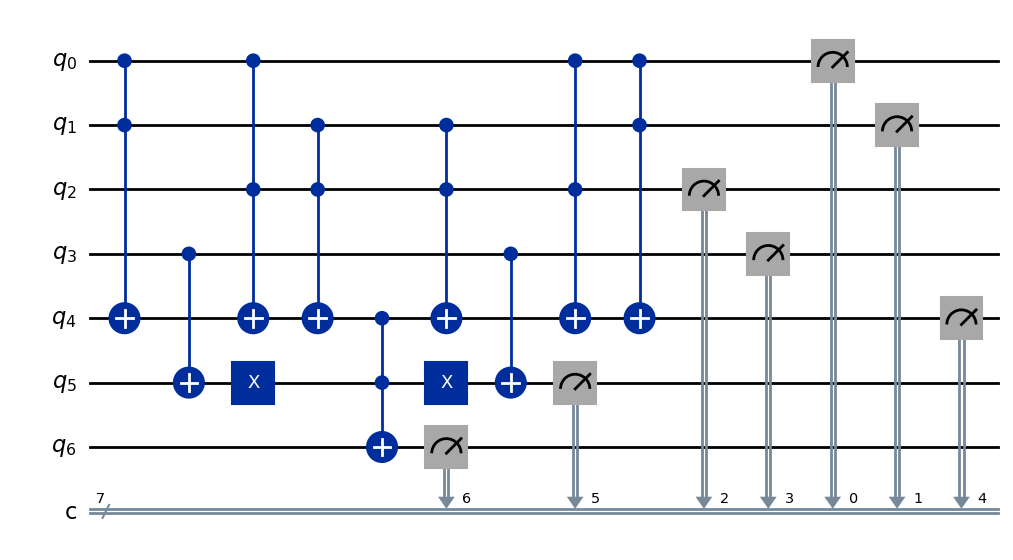

In [6]:
def build_basic_circuit():
    qr = QuantumRegister(7, 'q')
    cr = ClassicalRegister(7, 'c')
    qc = QuantumCircuit(qr, cr)

    # 1. MAJ(A,B,C) в q4
    qc.ccx(0, 1, 4)
    qc.ccx(0, 2, 4)
    qc.ccx(1, 2, 4)

    # 2. NOT D в q5
    qc.cx(3, 5)
    qc.x(5)

    # 3. F = MAJ AND NOT D в q6
    qc.ccx(4, 5, 6)

    # 4. Uncompute (возвращаем ancilla в |0>)
    qc.x(5)
    qc.cx(3, 5)
    qc.ccx(1, 2, 4)
    qc.ccx(0, 2, 4)
    qc.ccx(0, 1, 4)

    qc.measure(qr, cr)
    return qc

basic_qc = build_basic_circuit()
print("Базовая схема (2 ancilla):")
display(basic_qc.draw('mpl'))

In [7]:
def test_basic_circuit():
    simulator = AerSimulator()

    # Схема без измерений для подстановки входов
    qc_no_measure = QuantumCircuit(7)
    qc_no_measure.ccx(0, 1, 4); qc_no_measure.ccx(0, 2, 4); qc_no_measure.ccx(1, 2, 4)
    qc_no_measure.cx(3, 5); qc_no_measure.x(5)
    qc_no_measure.ccx(4, 5, 6)
    qc_no_measure.x(5); qc_no_measure.cx(3, 5)
    qc_no_measure.ccx(1, 2, 4); qc_no_measure.ccx(0, 2, 4); qc_no_measure.ccx(0, 1, 4)

    print(f"\n--- Тестирование: Базовая схема (2 ancilla) ---")
    print(f"{'A':<3} {'B':<3} {'C':<3} {'D':<3} | {'F_class':<8} | {'F_quant':<8} | {'Ancilla':<10} | Status")
    print("-" * 65)

    all_passed = True
    for i in range(16):
        a = (i >> 0) & 1; b = (i >> 1) & 1; c = (i >> 2) & 1; d = (i >> 3) & 1
        f_class = build_classic_f(a, b, c, d)

        qc_run = QuantumCircuit(7, 7)
        if a: qc_run.x(0)
        if b: qc_run.x(1)
        if c: qc_run.x(2)
        if d: qc_run.x(3)

        qc_run.compose(qc_no_measure, inplace=True)
        qc_run.measure(range(7), range(7))

        job = simulator.run(transpile(qc_run, simulator), shots=100)
        counts = job.result().get_counts()
        most_freq = max(counts, key=counts.get)

        f_quant = int(most_freq[0])   # c6
        ancilla_4 = int(most_freq[2]) # c4
        ancilla_5 = int(most_freq[1]) # c5

        status = "OK" if (f_quant == f_class and ancilla_4 == 0 and ancilla_5 == 0) else "FAIL"
        if status == "FAIL": all_passed = False

        print(f"{a:<3} {b:<3} {c:<3} {d:<3} | {f_class:<8} | {f_quant:<8} | {ancilla_4},{ancilla_5:<8} | {status}")

    print(f"\nВсе тесты пройдены: {all_passed}")

test_basic_circuit()


--- Тестирование: Базовая схема (2 ancilla) ---
A   B   C   D   | F_class  | F_quant  | Ancilla    | Status
-----------------------------------------------------------------
0   0   0   0   | 0        | 0        | 0,0        | OK
1   0   0   0   | 0        | 0        | 0,0        | OK
0   1   0   0   | 0        | 0        | 0,0        | OK
1   1   0   0   | 1        | 1        | 0,0        | OK
0   0   1   0   | 0        | 0        | 0,0        | OK
1   0   1   0   | 1        | 1        | 0,0        | OK
0   1   1   0   | 1        | 1        | 0,0        | OK
1   1   1   0   | 1        | 1        | 0,0        | OK
0   0   0   1   | 0        | 0        | 0,0        | OK
1   0   0   1   | 0        | 0        | 0,0        | OK
0   1   0   1   | 0        | 0        | 0,0        | OK
1   1   0   1   | 0        | 0        | 0,0        | OK
0   0   1   1   | 0        | 0        | 0,0        | OK
1   0   1   1   | 0        | 0        | 0,0        | OK
0   1   1   1   | 0        | 0        | 0


Оптимизированная схема (1 ancilla):


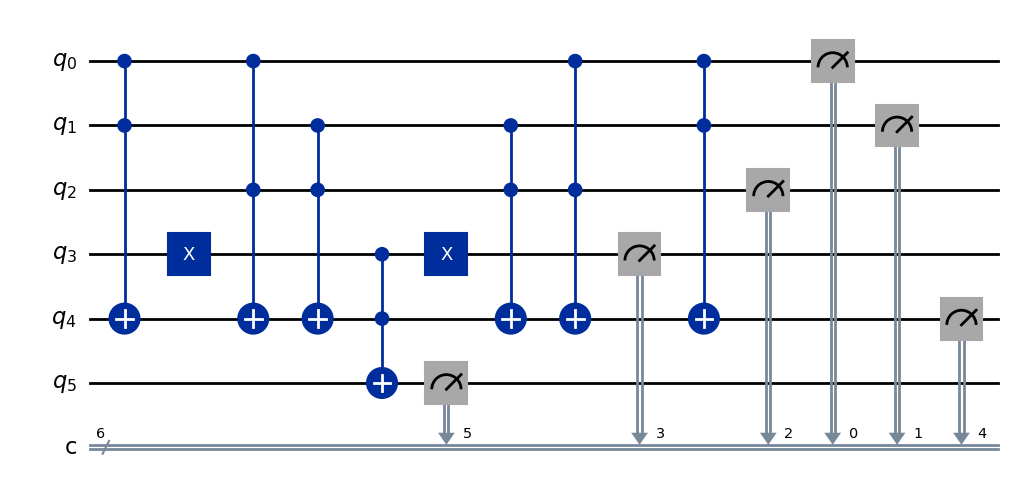


--- Сравнение схем ---
Параметр                  | Базовая         | Оптимизированная
------------------------------------------------------------
Кубиты (всего)            | 7               | 6              
Ancilla кубиты            | 2               | 1              
Вентили CX                | 2               | 0              
Вентили CCX               | 7               | 7              
Глубина                   | 7               | 7              


In [8]:
def build_optimized_circuit():
    qr = QuantumRegister(6, 'q')
    cr = ClassicalRegister(6, 'c')
    qc = QuantumCircuit(qr, cr)

    # 1. MAJ(A,B,C) в q4
    qc.ccx(0, 1, 4); qc.ccx(0, 2, 4); qc.ccx(1, 2, 4)

    # 2. Инвертируем D для получения NOT D
    qc.x(3)

    # 3. F = MAJ AND NOT D
    qc.ccx(4, 3, 5)

    # 4. Возвращаем D обратно
    qc.x(3)

    # 5. Uncompute (сбрасываем q4 в ноль)
    qc.ccx(1, 2, 4); qc.ccx(0, 2, 4); qc.ccx(0, 1, 4)

    qc.measure(qr, cr)
    return qc

opt_qc = build_optimized_circuit()
print("\nОптимизированная схема (1 ancilla):")
display(opt_qc.draw('mpl'))

# --- Сравнение схем ---
basic_no_m = QuantumCircuit(7)
basic_no_m.ccx(0, 1, 4); basic_no_m.ccx(0, 2, 4); basic_no_m.ccx(1, 2, 4)
basic_no_m.cx(3, 5); basic_no_m.x(5)
basic_no_m.ccx(4, 5, 6)
basic_no_m.x(5); basic_no_m.cx(3, 5)
basic_no_m.ccx(1, 2, 4); basic_no_m.ccx(0, 2, 4); basic_no_m.ccx(0, 1, 4)

opt_no_m = QuantumCircuit(6)
opt_no_m.ccx(0, 1, 4); opt_no_m.ccx(0, 2, 4); opt_no_m.ccx(1, 2, 4)
opt_no_m.x(3)
opt_no_m.ccx(4, 3, 5)
opt_no_m.x(3)
opt_no_m.ccx(1, 2, 4); opt_no_m.ccx(0, 2, 4); opt_no_m.ccx(0, 1, 4)

print("\n--- Сравнение схем ---")
print(f"{'Параметр':<25} | {'Базовая':<15} | {'Оптимизированная':<15}")
print("-" * 60)
print(f"{'Кубиты (всего)':<25} | {basic_no_m.num_qubits:<15} | {opt_no_m.num_qubits:<15}")
print(f"{'Ancilla кубиты':<25} | {2:<15} | {1:<15}")
print(f"{'Вентили CX':<25} | {basic_no_m.count_ops().get('cx', 0):<15} | {opt_no_m.count_ops().get('cx', 0):<15}")
print(f"{'Вентили CCX':<25} | {basic_no_m.count_ops().get('ccx', 0):<15} | {opt_no_m.count_ops().get('ccx', 0):<15}")
print(f"{'Глубина':<25} | {basic_no_m.depth():<15} | {opt_no_m.depth():<15}")

In [9]:
def test_optimized_circuit():
    simulator = AerSimulator()

    qc_no_measure = QuantumCircuit(6)
    qc_no_measure.ccx(0, 1, 4); qc_no_measure.ccx(0, 2, 4); qc_no_measure.ccx(1, 2, 4)
    qc_no_measure.x(3)
    qc_no_measure.ccx(4, 3, 5)
    qc_no_measure.x(3)
    qc_no_measure.ccx(1, 2, 4); qc_no_measure.ccx(0, 2, 4); qc_no_measure.ccx(0, 1, 4)

    print(f"\n--- Тестирование: Оптимизированная схема (1 ancilla) ---")
    print(f"{'A':<3} {'B':<3} {'C':<3} {'D':<3} | {'F_class':<8} | {'F_quant':<8} | {'Ancilla':<10} | Status")
    print("-" * 65)

    all_passed = True
    for i in range(16):
        a = (i >> 0) & 1; b = (i >> 1) & 1; c = (i >> 2) & 1; d = (i >> 3) & 1
        f_class = build_classic_f(a, b, c, d)

        qc_run = QuantumCircuit(6, 6)
        if a: qc_run.x(0)
        if b: qc_run.x(1)
        if c: qc_run.x(2)
        if d: qc_run.x(3)

        qc_run.compose(qc_no_measure, inplace=True)
        qc_run.measure(range(6), range(6))

        job = simulator.run(transpile(qc_run, simulator), shots=100)
        counts = job.result().get_counts()
        most_freq = max(counts, key=counts.get)

        f_quant = int(most_freq[0])   # c5
        ancilla = int(most_freq[1])   # c4

        status = "OK" if (f_quant == f_class and ancilla == 0) else "FAIL"
        if status == "FAIL": all_passed = False

        print(f"{a:<3} {b:<3} {c:<3} {d:<3} | {f_class:<8} | {f_quant:<8} | {ancilla:<10} | {status}")

    print(f"\nВсе тесты пройдены: {all_passed}")

test_optimized_circuit()


--- Тестирование: Оптимизированная схема (1 ancilla) ---
A   B   C   D   | F_class  | F_quant  | Ancilla    | Status
-----------------------------------------------------------------
0   0   0   0   | 0        | 0        | 0          | OK
1   0   0   0   | 0        | 0        | 0          | OK
0   1   0   0   | 0        | 0        | 0          | OK
1   1   0   0   | 1        | 1        | 0          | OK
0   0   1   0   | 0        | 0        | 0          | OK
1   0   1   0   | 1        | 1        | 0          | OK
0   1   1   0   | 1        | 1        | 0          | OK
1   1   1   0   | 1        | 1        | 0          | OK
0   0   0   1   | 0        | 0        | 0          | OK
1   0   0   1   | 0        | 0        | 0          | OK
0   1   0   1   | 0        | 0        | 0          | OK
1   1   0   1   | 0        | 0        | 0          | OK
0   0   1   1   | 0        | 0        | 0          | OK
1   0   1   1   | 0        | 0        | 0          | OK
0   1   1   1   | 0        | 0  

Запуск симуляции с шумом (может занять пару минут)...


/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


p2 = 0.000: Доля правильных ответов = 100.00%
p2 = 0.001: Доля правильных ответов = 100.00%
p2 = 0.005: Доля правильных ответов = 100.00%
p2 = 0.010: Доля правильных ответов = 100.00%
p2 = 0.020: Доля правильных ответов = 100.00%


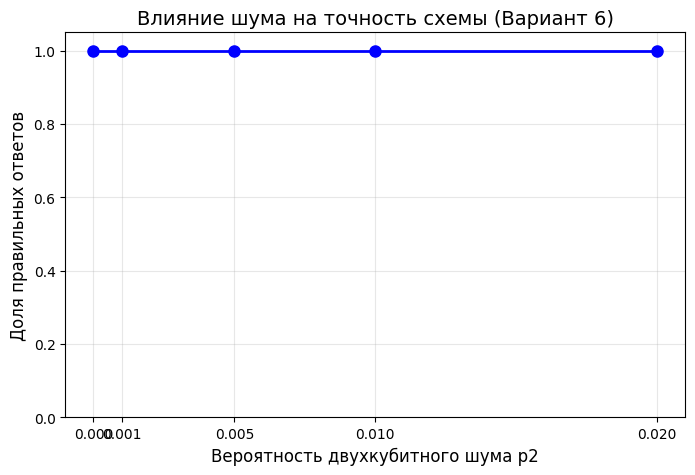

In [10]:
def simulate_noise(p2_values, p1=0.001):
    simulator = AerSimulator()

    # Берем оптимизированную схему без измерений
    qc_no_m = QuantumCircuit(6)
    qc_no_m.ccx(0, 1, 4); qc_no_m.ccx(0, 2, 4); qc_no_m.ccx(1, 2, 4)
    qc_no_m.x(3)
    qc_no_m.ccx(4, 3, 5)
    qc_no_m.x(3)
    qc_no_m.ccx(1, 2, 4); qc_no_m.ccx(0, 2, 4); qc_no_m.ccx(0, 1, 4)

    # Переводим в базис симулятора (разлагаем CCX на CX)
    compiled_base = transpile(qc_no_m, simulator, basis_gates=['u3', 'cx'])

    results = []
    for p2 in p2_values:
        noise_model = NoiseModel()
        # Однокубитный шум
        error_1q = depolarizing_error(p1, 1)
        noise_model.add_all_qubit_quantum_error(error_1q, ['u3'])
        # Двухкубитный шум
        if p2 > 0:
            error_2q = depolarizing_error(p2, 2)
            noise_model.add_all_qubit_quantum_error(error_2q, ['cx'])

        correct_count = 0
        for i in range(16):
            a = (i >> 0) & 1; b = (i >> 1) & 1; c = (i >> 2) & 1; d = (i >> 3) & 1
            f_class = build_classic_f(a, b, c, d)

            qc_run = QuantumCircuit(6, 6)
            if a: qc_run.x(0)
            if b: qc_run.x(1)
            if c: qc_run.x(2)
            if d: qc_run.x(3)
            qc_run.compose(compiled_base, inplace=True)
            qc_run.measure(range(6), range(6))

            job = simulator.run(qc_run, noise_model=noise_model, shots=1024)
            counts = job.result().get_counts()
            most_freq = max(counts, key=counts.get)
            f_quant = int(most_freq[0])

            if f_quant == f_class:
                correct_count += 1

        accuracy = correct_count / 16
        results.append((p2, accuracy))
        print(f"p2 = {p2:.3f}: Доля правильных ответов = {accuracy:.2%}")

    # Построение графика
    p2_list = [r[0] for r in results]
    acc_list = [r[1] for r in results]

    plt.figure(figsize=(8, 5))
    plt.plot(p2_list, acc_list, 'o-', color='blue', linewidth=2, markersize=8)
    plt.xlabel('Вероятность двухкубитного шума p2', fontsize=12)
    plt.ylabel('Доля правильных ответов', fontsize=12)
    plt.title('Влияние шума на точность схемы (Вариант 6)', fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.ylim(0, 1.05)
    plt.xticks(p2_list)
    plt.show()

p2_vals = [0, 0.001, 0.005, 0.01, 0.02]
print("Запуск симуляции с шумом (может занять пару минут)...")
simulate_noise(p2_vals)